In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal

In [ ]:
df = pd.read_csv("../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)

In [ ]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, 252, 0.001)

#### 89 Trade Count Strategy

In [34]:
lookback = 252

In [69]:
def generate_random_signal_v3(prices, lookback):

    possible_trade_days = np.arange(lookback + 1, len(prices) - 1)

    trade_days = np.random.choice(possible_trade_days, size = 89, replace = False)
    trade_days = np.sort(trade_days)

    random_signal = [np.nan] * lookback

    state = 0

    for i in range(lookback, len(prices)):
        if i in trade_days:
            state = 1 - state

        random_signal.append(state) 

    return random_signal

In [70]:
random_signal = generate_random_signal_v3(prices, lookback)

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return          3.151045
cagr                  0.057095
annual_volatility     0.148681
annual_sharpe         0.447889
max_drawdown         -0.488434
calmar                0.116893
time_invested         0.504954
trades               89.000000
dtype: float64

In [71]:
def run_simulation_v3(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v3(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [109]:
np.random.seed(44)

simulation_output = run_simulation_v3(10000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.094666,0.045053,0.108100,0.462097,-0.291098,0.154771,0.416254,89
1,6.207126,0.080092,0.114809,0.728532,-0.221963,0.360834,0.510217,89
2,1.315091,0.033288,0.132055,0.313943,-0.438860,0.075852,0.418731,89
3,1.096232,0.029293,0.117943,0.303794,-0.306537,0.095562,0.481424,89
4,1.217444,0.031553,0.134885,0.297689,-0.479669,0.065780,0.487461,89
...,...,...,...,...,...,...,...,...
9995,2.568384,0.050876,0.124773,0.460222,-0.394264,0.129041,0.416563,89
9996,1.656211,0.038844,0.139227,0.343131,-0.524782,0.074019,0.549690,89
9997,1.782186,0.040723,0.130828,0.370694,-0.392821,0.103668,0.525542,89
9998,1.281855,0.032706,0.138097,0.301996,-0.535171,0.061113,0.497988,89


In [110]:
print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

Sharpe Average: 0.3736
Sharpe Median:  0.3674
Largest Sharpe: 0.8708
Average No. of Trades: 89.0000
Average Time Invested: 0.5006


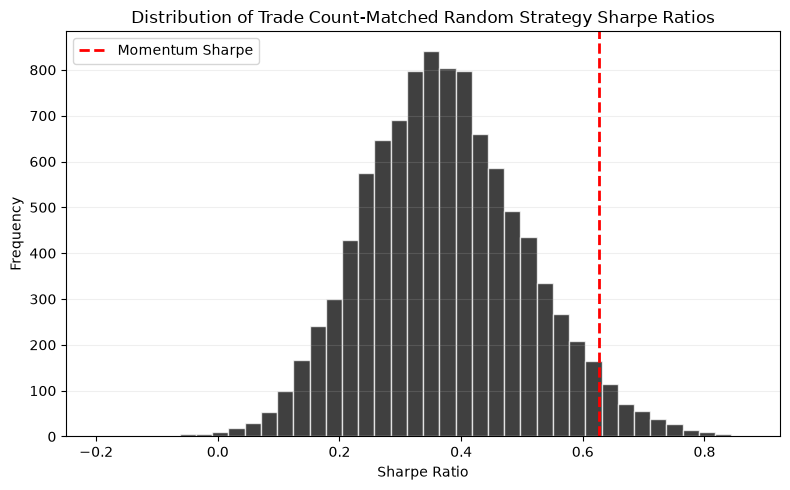

In [111]:
plt.figure(figsize=(8, 5))

plt.hist(
    simulation_df["annual_sharpe"],
    bins=40,
    color="black",
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    momentum_results["annual_sharpe"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Momentum Sharpe"
)

plt.xlabel("Sharpe Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Trade Count-Matched Random Strategy Sharpe Ratios")

plt.legend()

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()